# 03 · Customer & account behaviour, anomaly patterns
Feature groups: **Customer & Account Behaviour**, **Anomaly Patterns**.
For anomalies the aim is the *generating condition* of each label (what the generator did to a normal payment), not a detector.

In [24]:
import sys; sys.path.insert(0, '../src')
from utils import q, rule_check, savefig, export
import numpy as np, pandas as pd, matplotlib.pyplot as plt

## A. Customers and accounts
### H-A1  Flow mix is the product of independent sender-type and receiver-type choices

In [25]:
fl = q('SELECT ORDERING_TYPE o, BENEFICIARY_TYPE b, count(*) n FROM f GROUP BY ALL ORDER BY 1,2'); N = fl.n.sum()
fl['share'] = fl.n/N; fl['expected_if_independent'] = fl.groupby('o').n.transform('sum')*fl.groupby('b').n.transform('sum')/N**2
export(fl,'party_flow_mix'); fl

,o,b,n,share,expected_if_independent
0,B,B,2270945,0.227095,0.226912
1,B,C,5603692,0.560369,0.560552
2,C,B,610605,0.061060,0.061243
3,C,C,1514758,0.151476,0.151293


### H-A2  Accounts have a fixed type and a fixed bank; senders are a small, busy population and receivers a large one

In [26]:
pd.concat([
  rule_check('ordering account -> one ORDERING_TYPE', 'n=1', table="(SELECT count(DISTINCT ORDERING_TYPE) n FROM f GROUP BY ORDERING_ACCOUNT)"),
  rule_check('ordering account -> one ORDERING_BIC8', 'n=1', table="(SELECT count(DISTINCT ORDERING_BIC8) n FROM f GROUP BY ORDERING_ACCOUNT)"),
  rule_check('beneficiary account -> one BENEFICIARY_TYPE', 'n=1', table="(SELECT count(DISTINCT BENEFICIARY_TYPE) n FROM f GROUP BY BENEFICIARY_ACCOUNT)"),
  rule_check('beneficiary account -> one BENEFICIARY_BIC8', 'n=1', table="(SELECT count(DISTINCT BENEFICIARY_BIC8) n FROM f GROUP BY BENEFICIARY_ACCOUNT)"),
  rule_check('ordering account -> one ORDERING_DETAILS text', 'n=1', table="(SELECT count(DISTINCT ORDERING_DETAILS) n FROM p GROUP BY ORDERING_ACCOUNT)"),
  rule_check('sender accounts that also receive', 'x', table="(SELECT a.acc IN (SELECT DISTINCT BENEFICIARY_ACCOUNT FROM f) AS x FROM (SELECT DISTINCT ORDERING_ACCOUNT acc FROM f) a)"),
])

,rule,rows_in_scope,rows_matching,match_rate_pct,exceptions
0,ordering account -> one ORDERING_TYPE,391132,391132.0,100.0000,0.0
0,ordering account -> one ORDERING_BIC8,391132,391132.0,100.0000,0.0
0,beneficiary account -> one BENEFICIARY_TYPE,2590877,2590877.0,100.0000,0.0
0,beneficiary account -> one BENEFICIARY_BIC8,2590877,2529271.0,97.6222,61606.0
0,ordering account -> one ORDERING_DETAILS text,391132,233804.0,59.7762,157328.0
0,sender accounts that also receive,391132,253120.0,64.7147,138012.0


In [27]:
act = q('''SELECT ORDERING_TYPE, count(*) accounts, avg(n) mean_payments, median(n) median_payments, max(n) max_payments,
                  avg(partners) mean_distinct_receivers
           FROM (SELECT ORDERING_ACCOUNT, any_value(ORDERING_TYPE) ORDERING_TYPE, count(*) n, count(DISTINCT BENEFICIARY_ACCOUNT) partners
                 FROM f GROUP BY 1) GROUP BY 1'''); export(act,'party_sender_activity'); act

,ORDERING_TYPE,accounts,mean_payments,median_payments,max_payments,mean_distinct_receivers
0,B,175609,44.841876,4.0,75803,36.344977
1,C,215523,9.861421,2.0,14551,8.722637


In [28]:
rep = q('''SELECT least(n,6) AS payments_per_pair, count(*) pairs, sum(n) payments FROM
             (SELECT count(*) n FROM f WHERE NOT IS_ANOMALY GROUP BY ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT) GROUP BY 1 ORDER BY 1''')
rep['share_of_payments'] = rep.payments/rep.payments.sum(); export(rep,'party_repeat_pairs'); rep

,payments_per_pair,pairs,payments,share_of_payments
0,1,7629902,7629902.0,0.763525
1,2,379642,759284.0,0.075982
2,3,107371,322113.0,0.032234
3,4,47098,188392.0,0.018852
4,5,25902,129510.0,0.012960
5,6,68565,963793.0,0.096447


### H-A3  The account format depends on the bank's country (IBAN countries vs free-format countries), not on the customer type

In [29]:
ib = q('''SELECT ORD_COUNTRY, count(*) n, avg(ORD_ACC_IS_IBAN::int) share_iban FROM f GROUP BY 1 HAVING count(*)>=20000''')
print(ib.share_iban.round(1).value_counts().sort_index()); 
q('SELECT ORDERING_TYPE, avg(ORD_ACC_IS_IBAN::int) share_iban, count(*) n FROM f GROUP BY 1')

share_iban
0.0    27
1.0    35
Name: count, dtype: int64


,ORDERING_TYPE,share_iban,n
0,B,0.534883,7874637
1,C,0.579016,2125363


### H-A4  Party details: tokens follow the party type (business keywords for B, first/last names for C); is the country in the details the bank's country?

In [30]:
q('''SELECT ORDERING_TYPE,
            avg(contains(ORDERING_TOKENS,'<business')::int) has_business_token, avg(contains(ORDERING_TOKENS,'<company_keyword')::int) has_company_keyword,
            avg(contains(ORDERING_TOKENS,'<first_name')::int) has_first_name, avg(contains(ORDERING_TOKENS,'<last_name')::int) has_last_name,
            avg(contains(ORDERING_TOKENS,'<line_break')::int) has_line_break, avg(contains(ORDERING_TOKENS,'<country_code')::int) has_country_code
     FROM p GROUP BY 1''')

,ORDERING_TYPE,has_business_token,has_company_keyword,has_first_name,has_last_name,has_line_break,has_country_code
0,B,0.853809,0.263069,0.000000,0.000000,0.46499,0.605181
1,C,0.000000,0.000000,0.571349,0.861025,0.46860,0.620606


In [31]:
pd.concat([rule_check('details country = ordering bank country', 'ORD_DETAILS_COUNTRY = ORD_COUNTRY', 'ORD_DETAILS_COUNTRY IS NOT NULL'),
           rule_check('details country = beneficiary bank country', 'BEN_DETAILS_COUNTRY = BEN_COUNTRY', 'BEN_DETAILS_COUNTRY IS NOT NULL')])

,rule,rows_in_scope,rows_matching,match_rate_pct,exceptions
0,details country = ordering bank country,6084595,6084595.0,100.0000,0.0
0,details country = beneficiary bank country,6107358,59826.0,0.9796,6047532.0


## B. Anomalies
### Overview: labels, frequency, who is involved

In [32]:
ov = q('''SELECT ANOMALY, count(*) n, round(1e6*count(*)/sum(count(*)) OVER ()) AS per_million,
                 count(DISTINCT ORDERING_ACCOUNT) senders, count(DISTINCT BENEFICIARY_ACCOUNT) receivers,
                 avg((ORDERING_TYPE='B')::int) sender_is_B, avg((BENEFICIARY_TYPE='B')::int) receiver_is_B,
                 median(USD_AMOUNT) median_usd, median(TOTAL_DURATION) median_duration, avg(IS_DOMESTIC::int) domestic
          FROM f GROUP BY 1 ORDER BY n DESC'''); export(ov,'anomaly_overview'); ov

,ANOMALY,n,per_million,senders,receivers,sender_is_B,receiver_is_B,median_usd,median_duration,domestic
0,NONE,9992994,999299.0,390725,2589757,0.787637,0.288167,3662.58,56.0,0.071132
1,ROMANCE_SCAM,2476,248.0,500,378,0.000000,0.268578,109.45,1148.0,0.030291
2,FAT_FINGER_MISTAKE,1940,194.0,1740,1823,0.795361,0.281443,260241.23,53.0,0.065979
3,CEO_SCAM,945,95.0,891,634,1.000000,0.277249,20602.13,741.0,0.012698
4,DUPLICATE_PAYMENT,679,68.0,183,184,0.802651,0.254786,2888.63,261.0,0.082474
5,ACCOUNT_REPLACEMENT_SCAM,649,65.0,622,462,0.782743,0.265023,3977.30,571.0,0.006163
6,CUSTOMER_RECALL,317,32.0,306,311,0.776025,0.268139,3163.97,53.0,0.053628


`CUSTOMER_RECALL` appears in the data but is **not described in the case study** — logged as a data issue and analysed like the others.

### H-B1  FAT_FINGER: a normal payment whose amount was multiplied by a power of 10 (decimal separator moved)

In [33]:
ff = q('''WITH a AS (SELECT * FROM f WHERE ANOMALY='FAT_FINGER_MISTAKE'),
               ref AS (SELECT ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT, median(USD_AMOUNT) med, count(*) c FROM f WHERE NOT IS_ANOMALY GROUP BY ALL)
          SELECT a.ROW_ID, a.FLOW, a.CURRENCY_CODE, a.USD_AMOUNT, ref.med AS usual_pair_amount, ref.c AS n_normal_in_pair, log10(a.USD_AMOUNT/ref.med) AS log10_ratio
          FROM a LEFT JOIN ref USING (ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT)''')
print('fat-finger rows:', len(ff), '| with a normal payment in the same sender-receiver pair:', ff.usual_pair_amount.notna().sum())
ff.log10_ratio.describe()

fat-finger rows: 1940 | with a normal payment in the same sender-receiver pair: 460


count    460.000000
mean       1.519365
std        2.361817
min       -4.777409
25%       -0.023980
50%        1.848818
75%        3.195510
max        6.602120
Name: log10_ratio, dtype: float64

count    1940.000000
mean        1.553010
std         2.249387
min        -4.568732
25%         0.137945
50%         1.903345
75%         3.256772
max         6.570831
Name: shift, dtype: float64
share below normal mean: 0.241


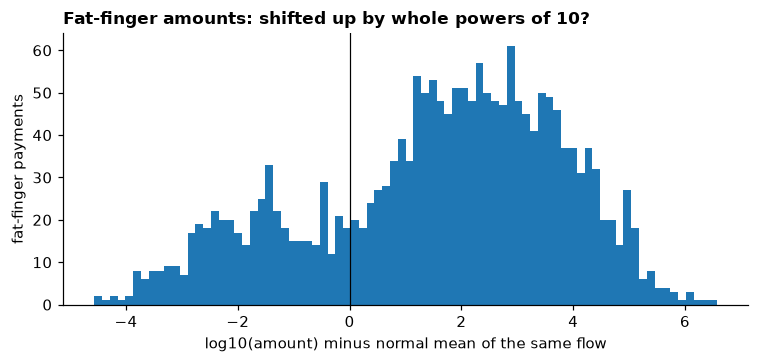

In [34]:
# cleaner baseline: the flow x currency amount distribution. shift of the anomalous amounts in log10 units
base = q('''SELECT FLOW, avg(LOG10_USD) mu, stddev(LOG10_USD) sd FROM f WHERE NOT IS_ANOMALY GROUP BY 1''').set_index('FLOW')
z = q("SELECT FLOW, LOG10_USD FROM f WHERE ANOMALY='FAT_FINGER_MISTAKE'"); z['shift'] = z.LOG10_USD - z.FLOW.map(base.mu)
fig, ax = plt.subplots(figsize=(7,3.4)); ax.hist(z['shift'], bins=80); ax.axvline(0, color='k', lw=.8)
ax.set_xlabel('log10(amount) minus normal mean of the same flow'); ax.set_ylabel('fat-finger payments')
ax.set_title('Fat-finger amounts: shifted up by whole powers of 10?'); savefig('B1_fat_finger_shift')
print(z['shift'].describe()); print('share below normal mean:', (z['shift']<0).mean().round(3))

In [35]:
# digits: does the amount look like a normal amount with the separator moved? (e.g. 1234.56 -> 123456.00)
q('''SELECT ANOMALY, count(*) n,
            avg((round(USD_AMOUNT*100)::bigint % 100 = 0)::int) AS share_whole_units,
            avg((round(USD_AMOUNT*100)::bigint % 10 = 0)::int) AS share_last_cent_digit_zero,
            avg((USD_AMOUNT < 1)::int) AS share_below_1usd
     FROM f WHERE ANOMALY IN ('FAT_FINGER_MISTAKE','NONE') GROUP BY 1''')

,ANOMALY,n,share_whole_units,share_last_cent_digit_zero,share_below_1usd
0,FAT_FINGER_MISTAKE,1940,0.135052,0.223196,0.012371
1,NONE,9992994,0.074008,0.158400,0.001165


### H-B2  DUPLICATE_PAYMENT: an exact copy of another payment (same accounts, amount, currency) a short time later

In [36]:
dup = q('''WITH a AS (SELECT * FROM f WHERE ANOMALY='DUPLICATE_PAYMENT')
           SELECT a.ROW_ID, a.ORDERING_TYPE, count(o.ROW_ID) AS n_twins, min(abs(a.EPOCH_SECONDS-o.EPOCH_SECONDS)) AS nearest_twin_seconds,
                  bool_and(o.ANOMALY='DUPLICATE_PAYMENT') AS all_twins_labelled_duplicate, bool_and(o.BIC8_PATH=a.BIC8_PATH) AS same_path
           FROM a LEFT JOIN f o ON o.ORDERING_ACCOUNT=a.ORDERING_ACCOUNT AND o.BENEFICIARY_ACCOUNT=a.BENEFICIARY_ACCOUNT
                                AND o.USD_AMOUNT=a.USD_AMOUNT AND o.CURRENCY_CODE=a.CURRENCY_CODE AND o.ROW_ID<>a.ROW_ID GROUP BY ALL''')
print(dup.n_twins.value_counts().sort_index()); print(dup[['all_twins_labelled_duplicate','same_path']].mean())
dup.groupby('ORDERING_TYPE').nearest_twin_seconds.describe()

n_twins
1     74
2    129
3    196
4    280
Name: count, dtype: int64
all_twins_labelled_duplicate    1.0
same_path                       1.0
dtype: float64


,count,mean,std,min,25%,50%,75%,max
ORDERING_TYPE,,,,,,,,
B,545.0,1221.611009,1324.725873,1.0,288.0,749.0,1633.0,6940.0
C,134.0,1008.261194,1042.771769,0.0,246.0,673.5,1457.0,4934.0


In [37]:
# group structure: how many copies per duplicated payment, and how far apart in time
grp = q('''SELECT ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT, USD_AMOUNT, any_value(ORDERING_TYPE) ot, count(*) copies,
                  max(EPOCH_SECONDS)-min(EPOCH_SECONDS) span_s, count(DISTINCT TOTAL_DURATION) n_durations
           FROM f WHERE ANOMALY='DUPLICATE_PAYMENT' GROUP BY ALL''')
print(grp.copies.value_counts().sort_index()); grp.groupby('ot')[['copies','span_s']].describe().T

copies
2    37
3    43
4    49
5    56
Name: count, dtype: int64


ot                      B            C
copies count   149.000000    36.000000
       mean      3.657718     3.722222
       std       1.107541     1.136690
       min       2.000000     2.000000
       25%       3.000000     3.000000
       50%       4.000000     4.000000
       75%       5.000000     5.000000
       max       5.000000     5.000000
span_s count   149.000000    36.000000
       mean   3961.000000  3661.722222
       std    1633.272788  1760.255706
       min     203.000000   413.000000
       25%    2885.000000  2236.000000
       50%    4089.000000  3434.000000
       75%    5163.000000  5155.750000
       max    7039.000000  7043.000000

In [38]:
# converse: are there unlabelled exact repeats among NORMAL payments? (is the label reconstructable?)
q('''SELECT count(*) AS normal_groups_with_same_pair_amount_within_2h FROM (
       SELECT ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT, USD_AMOUNT FROM f WHERE NOT IS_ANOMALY
       GROUP BY ALL HAVING count(*)>1 AND max(EPOCH_SECONDS)-min(EPOCH_SECONDS) < 7200)''')

,normal_groups_with_same_pair_amount_within_2h
0,129


### H-B3  ROMANCE_SCAM: one consumer pays the same receiver several times within minutes/hours, with amounts escalating

In [39]:
rs = q('''SELECT ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT, any_value(FLOW) flow, count(*) payments,
                 (max(EPOCH_SECONDS)-min(EPOCH_SECONDS))/60.0 AS span_minutes,
                 arg_min(USD_AMOUNT, EPOCH_SECONDS) first_amt, arg_max(USD_AMOUNT, EPOCH_SECONDS) last_amt, sum(USD_AMOUNT) total
          FROM f WHERE ANOMALY='ROMANCE_SCAM' GROUP BY ALL''')
rs['last_over_first'] = rs.last_amt/rs.first_amt
print('scam episodes:', len(rs)); print(rs.payments.value_counts().sort_index()); rs[['span_minutes','first_amt','last_amt','last_over_first','total']].describe()

scam episodes: 500
payments
2    61
3    95
4    64
5    71
6    74
7    66
8    69
Name: count, dtype: int64


,span_minutes,first_amt,last_amt,last_over_first,total
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,20.183400,473.194980,3483.412160,7.405806,9697.760360
std,14.153912,1377.367633,11919.568927,7.052643,33720.600588
min,0.000000,0.010000,0.010000,0.500000,0.030000
25%,9.195833,4.917500,17.692500,2.336282,42.450000
50%,17.791667,33.270000,191.085000,4.876436,529.740000
75%,29.179167,265.525000,1471.530000,10.136298,3966.095000
max,69.850000,19769.320000,123370.390000,38.872014,377009.620000


In [40]:
seq = q('''SELECT row_number() OVER (PARTITION BY ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT ORDER BY EPOCH_SECONDS) AS step,
                  USD_AMOUNT / first_value(USD_AMOUNT) OVER (PARTITION BY ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT ORDER BY EPOCH_SECONDS) AS rel,
                  USD_AMOUNT / lag(USD_AMOUNT) OVER (PARTITION BY ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT ORDER BY EPOCH_SECONDS) AS step_ratio,
                  EPOCH_SECONDS - lag(EPOCH_SECONDS) OVER (PARTITION BY ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT ORDER BY EPOCH_SECONDS) AS gap_s
           FROM f WHERE ANOMALY='ROMANCE_SCAM' ''')
s = seq.groupby('step').agg(n=('rel','size'), median_rel_amount=('rel','median'), median_step_ratio=('step_ratio','median'), median_gap_s=('gap_s','median'))
export(s.reset_index(),'anomaly_romance_escalation'); s

,n,median_rel_amount,median_step_ratio,median_gap_s
step,,,,
1,500,1.000000,NaN,<NA>
2,500,1.497345,1.497345,214.5
3,439,2.257143,1.500000,218.0
4,344,3.485111,1.459909,213.5
5,280,5.204453,1.508624,246.5
6,209,8.085106,1.550933,186.0
7,135,11.810640,1.534396,207.0
8,69,18.056232,1.455328,257.0


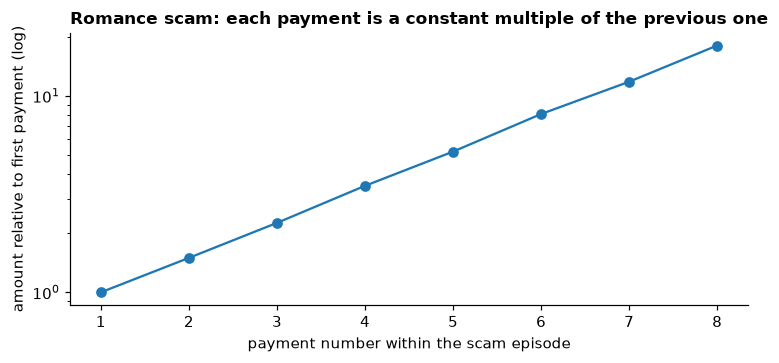

In [41]:
fig, ax = plt.subplots(figsize=(7,3.4)); ax.semilogy(s.index, s.median_rel_amount, 'o-')
ax.set_xlabel('payment number within the scam episode'); ax.set_ylabel('amount relative to first payment (log)')
ax.set_title('Romance scam: each payment is a constant multiple of the previous one'); savefig('B3_romance_escalation')

In [42]:
# were sender and receiver in contact before? is the receiver a dedicated scam account?
q('''WITH e AS (SELECT ORDERING_ACCOUNT oa, BENEFICIARY_ACCOUNT ba, min(EPOCH_SECONDS) t0 FROM f WHERE ANOMALY='ROMANCE_SCAM' GROUP BY ALL)
     SELECT count(*) episodes,
            avg((SELECT count(*) FROM f WHERE ORDERING_ACCOUNT=e.oa AND NOT IS_ANOMALY)) AS sender_normal_payments,
            avg((SELECT count(*) FROM f WHERE BENEFICIARY_ACCOUNT=e.ba AND NOT IS_ANOMALY)) AS receiver_normal_receipts,
            avg((SELECT count(*) FROM f WHERE ORDERING_ACCOUNT=e.oa AND BENEFICIARY_ACCOUNT=e.ba AND NOT IS_ANOMALY)) AS pair_normal_payments
     FROM e''')

,episodes,sender_normal_payments,receiver_normal_receipts,pair_normal_payments
0,500,2.29,3.126,0.0


### H-B4  CEO_SCAM and ACCOUNT_REPLACEMENT_SCAM: a business pays a receiver it has no history with
Account replacement should look like a *usual* payment (same amount range, same details) going to a *new* account; CEO scam like an unusually large one-off.

In [43]:
q('''WITH hist AS (SELECT ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT, count(*) FILTER (NOT IS_ANOMALY) AS normal_in_pair FROM f GROUP BY ALL),
          ben AS (SELECT BENEFICIARY_ACCOUNT, count(*) FILTER (NOT IS_ANOMALY) AS ben_normal, count(DISTINCT ORDERING_ACCOUNT) ben_senders FROM f GROUP BY 1),
          snd AS (SELECT ORDERING_ACCOUNT, median(LOG10_USD) FILTER (NOT IS_ANOMALY) AS sender_usual_log FROM f GROUP BY 1)
     SELECT ANOMALY, count(*) n, avg((normal_in_pair=0)::int) AS pair_has_no_normal_history,
            avg((ben_normal=0)::int) AS receiver_has_no_normal_receipts, median(ben_senders) median_senders_of_receiver,
            median(LOG10_USD - sender_usual_log) AS median_log10_vs_sender_usual
     FROM f JOIN hist USING (ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT) JOIN ben USING (BENEFICIARY_ACCOUNT) JOIN snd USING (ORDERING_ACCOUNT)
     GROUP BY 1 ORDER BY 1''')

,ANOMALY,n,pair_has_no_normal_history,receiver_has_no_normal_receipts,median_senders_of_receiver,median_log10_vs_sender_usual
0,ACCOUNT_REPLACEMENT_SCAM,649,1.000000,0.469954,4.0,0.041493
1,CEO_SCAM,945,0.997884,0.483598,4.0,0.502503
2,CUSTOMER_RECALL,317,0.731861,0.182965,53.0,-0.058352
3,DUPLICATE_PAYMENT,679,0.804124,0.192931,49.0,-0.063055
4,FAT_FINGER_MISTAKE,1940,0.762887,0.205670,41.5,1.927255
5,NONE,9992994,0.000000,0.000000,41.0,0.000000
6,ROMANCE_SCAM,2476,1.000000,0.602989,3.0,0.150317


In [44]:
# account replacement: is there a 'legitimate twin' = same sender, same beneficiary DETAILS text, different beneficiary account?
q('''WITH a AS (SELECT ROW_ID, ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT, regexp_replace(BENEFICIARY_DETAILS,'^[^\n]*\n','') AS ben_body, USD_AMOUNT
               FROM p WHERE ANOMALY_TYPE='ACCOUNT_REPLACEMENT_SCAM'),
          o AS (SELECT ORDERING_ACCOUNT, BENEFICIARY_ACCOUNT, regexp_replace(BENEFICIARY_DETAILS,'^[^\n]*\n','') AS ben_body, USD_AMOUNT
               FROM p WHERE ANOMALY_TYPE IS NULL AND ORDERING_ACCOUNT IN (SELECT ORDERING_ACCOUNT FROM a))
     SELECT count(DISTINCT a.ROW_ID) AS scams_with_twin_same_name_other_account, (SELECT count(*) FROM a) AS scams_total,
            median(a.USD_AMOUNT/o.USD_AMOUNT) AS median_amount_ratio_to_twin
     FROM a JOIN o ON o.ORDERING_ACCOUNT=a.ORDERING_ACCOUNT AND o.ben_body=a.ben_body AND o.BENEFICIARY_ACCOUNT<>a.BENEFICIARY_ACCOUNT''')

,scams_with_twin_same_name_other_account,scams_total,median_amount_ratio_to_twin
0,0,649,NaN


In [45]:
q('''SELECT ANOMALY, FLOW, count(*) n, median(USD_AMOUNT) median_usd FROM f WHERE ANOMALY IN ('CEO_SCAM','ACCOUNT_REPLACEMENT_SCAM','CUSTOMER_RECALL') GROUP BY ALL ORDER BY 1,2''')

,ANOMALY,FLOW,n,median_usd
0,ACCOUNT_REPLACEMENT_SCAM,B2B,138,22385.065
1,ACCOUNT_REPLACEMENT_SCAM,B2C,370,3691.330
2,ACCOUNT_REPLACEMENT_SCAM,C2B,34,4493.785
3,ACCOUNT_REPLACEMENT_SCAM,C2C,107,476.020
4,CEO_SCAM,B2B,262,15178.245
5,CEO_SCAM,B2C,683,25556.020
6,CUSTOMER_RECALL,B2B,63,30026.650
7,CUSTOMER_RECALL,B2C,183,3379.250
8,CUSTOMER_RECALL,C2B,22,1319.580
9,CUSTOMER_RECALL,C2C,49,232.810


### Timing of anomalies vs normal traffic

In [46]:
t = q('''SELECT ANOMALY, avg(IS_WEEKEND::int) share_weekend, avg((HOUR_UTC BETWEEN 0 AND 5)::int) share_night_utc,
                median(TOTAL_DURATION) median_duration, avg(PARTICIPANT_COUNT) mean_participants, avg(HAS_GAP::int) share_gap
         FROM f GROUP BY 1 ORDER BY 1'''); export(t,'anomaly_timing_routing'); t

,ANOMALY,share_weekend,share_night_utc,median_duration,mean_participants,share_gap
0,ACCOUNT_REPLACEMENT_SCAM,0.104777,0.144838,571.0,2.510015,0.063174
1,CEO_SCAM,0.122751,0.133333,741.0,2.572487,0.071958
2,CUSTOMER_RECALL,0.097792,0.173502,53.0,2.624606,0.110410
3,DUPLICATE_PAYMENT,0.123711,0.162003,261.0,2.642121,0.067747
4,FAT_FINGER_MISTAKE,0.109794,0.159278,53.0,2.553608,0.069588
5,NONE,0.111843,0.155144,56.0,2.581577,0.076720
6,ROMANCE_SCAM,0.129241,0.197900,1148.0,2.581987,0.087237
